# Práctica: Redes Generativas Adversarias (GAN) con MNIST

**Objetivo.** Entrenar una GAN simple (generador + discriminador) que aprenda a producir dígitos manuscritos parecidos a los del conjunto MNIST, y analizar cómo evoluciona el entrenamiento adversarial.

**Cómo ejecutarlo en Google Colab**
1. Menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* (T4 o similar).
2. Menú *Entorno de ejecución → Ejecutar todas*.
3. Al final, la última celda genera `resultados_gan.zip` con las figuras y las métricas. Esos valores se copian en las secciones *Resultados* y *Análisis* del informe.

Duración aproximada con GPU: unos pocos minutos. Sin GPU (CPU) tardará bastante más.

**Qué hace el notebook**
- Carga MNIST y lo normaliza al rango [-1, 1].
- Define el generador *G* y el discriminador *D* (redes densas).
- Entrena ambas redes de forma alternada (juego minimax).
- Registra pérdidas y la probabilidad que *D* asigna a imágenes reales y falsas.
- Guarda muestras generadas durante el entrenamiento.
- Evalúa el resultado con *D*, con un clasificador auxiliar (para detectar colapso de modos) y con una interpolación en el espacio latente.

In [1]:
import os, json, random, time, zipfile
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# ---------------- Hiperparámetros (deben coincidir con el informe) ----------------
SEED       = 42
LATENT_DIM = 100          # tamaño del vector de ruido z
BATCH_SIZE = 128
EPOCHS     = 50
LR         = 2e-4
BETAS      = (0.5, 0.999) # Adam
SNAP_EPOCHS = [1, 5, 10, 25, 50]

OUT_DIR = "resultados_gan"
os.makedirs(OUT_DIR, exist_ok=True)

# Reproducibilidad
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Dispositivo:", device, "|", gpu_name)
if device.type == "cpu":
    print("AVISO: no hay GPU activa. Activa una en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")

Dispositivo: cuda | Tesla T4


## 1. Datos: MNIST

MNIST contiene imágenes de dígitos manuscritos (0-9) de 28×28 píxeles en escala de grises. Las imágenes se normalizan a [-1, 1] para que coincidan con la salida `Tanh` del generador. **Las etiquetas no se usan para entrenar la GAN** (aprendizaje no supervisado); solo se usan más adelante en el clasificador auxiliar de evaluación.

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.39MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.08MB/s]

Imágenes de entrenamiento: 60000 | de prueba: 10000


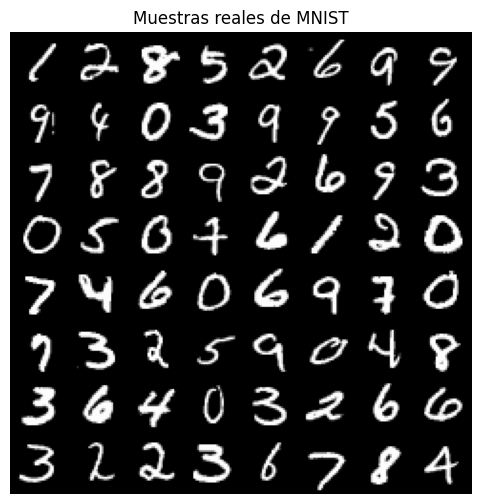

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),   # [0,1] -> [-1,1]
])

train_ds = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=2, pin_memory=(device.type == "cuda"))
test_loader  = DataLoader(test_ds, batch_size=1000, shuffle=False)

print("Imágenes de entrenamiento:", len(train_ds), "| de prueba:", len(test_ds))

def mostrar_cuadricula(imgs, titulo, nrow=8, nombre=None, size=6):
    # imgs en [-1,1], tensor (N,1,28,28)
    grid = make_grid((imgs.detach().cpu() + 1) / 2, nrow=nrow, padding=2)
    plt.figure(figsize=(size, size))
    plt.imshow(grid[0], cmap="gray")
    plt.title(titulo)
    plt.axis("off")
    if nombre:
        plt.savefig(os.path.join(OUT_DIR, nombre), dpi=150, bbox_inches="tight")
    plt.show()

reales, _ = next(iter(train_loader))
mostrar_cuadricula(reales[:64], "Muestras reales de MNIST", nombre="muestras_reales.png")

## 2. Modelos: generador y discriminador

- **Generador G(z):** recibe un vector de ruido `z` (dimensión 100) y lo transforma en una imagen 28×28. Capa final `Tanh` (salida en [-1, 1]).
- **Discriminador D(x):** recibe una imagen y devuelve un *logit*; `sigmoid(logit)` es la probabilidad de que la imagen sea **real**. Usa `Dropout` para que no se vuelva demasiado fuerte demasiado pronto (uno de los fallos típicos de las GAN).

In [3]:
class Generator(nn.Module):
    def __init__(self, z_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),  nn.LeakyReLU(0.2),
            nn.Linear(256, 512),    nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),   nn.LeakyReLU(0.2),
            nn.Linear(1024, 784),   nn.Tanh(),
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 1024), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(1024, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256),  nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1),    # logit (la sigmoide va dentro de la pérdida)
        )
    def forward(self, x):
        return self.net(x)


G = Generator().to(device)
D = Discriminator().to(device)

n_params_G = sum(p.numel() for p in G.parameters())
n_params_D = sum(p.numel() for p in D.parameters())
print(G)
print(D)
print(f"Parámetros -> Generador: {n_params_G:,} | Discriminador: {n_params_D:,}")

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=1024, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=512, out_features=256, bias=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=256, out_features=1, bias=True)
  )
)
Parámetros -

## 3. Entrenamiento adversarial

En cada iteración:

1. **Paso del discriminador:** se le muestra un lote de imágenes reales (etiqueta 1) y un lote de imágenes generadas (etiqueta 0). Se minimiza la entropía cruzada binaria. Las imágenes falsas se pasan con `detach()` para no actualizar a G en este paso.
2. **Paso del generador:** se le piden imágenes nuevas y se busca que D las clasifique como reales (etiqueta 1). Se usa la pérdida *no saturante* propuesta por Goodfellow et al. (2014): en lugar de minimizar `log(1 - D(G(z)))` se maximiza `log D(G(z))`, que da mejores gradientes al inicio.

Se registran por época: pérdida de D, pérdida de G, **D(x)** (probabilidad media asignada a imágenes reales) y **D(G(z))** (probabilidad media asignada a imágenes falsas). En el equilibrio teórico ambas tienden a 0.5.

In [4]:
criterion = nn.BCEWithLogitsLoss()
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS)

fixed_z = torch.randn(64, LATENT_DIM, device=device)   # mismo ruido para ver la evolución
history = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": []}
snapshots = {}

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    s_d = s_g = s_dx = s_dgz = 0.0
    n_batches = 0

    for real, _ in train_loader:
        real = real.to(device)
        b = real.size(0)
        ones  = torch.ones(b, 1, device=device)
        zeros = torch.zeros(b, 1, device=device)

        # ---------- 1) Entrenar D ----------
        z = torch.randn(b, LATENT_DIM, device=device)
        fake = G(z)
        logits_real = D(real)
        logits_fake = D(fake.detach())
        d_loss = criterion(logits_real, ones) + criterion(logits_fake, zeros)
        opt_D.zero_grad()
        d_loss.backward()
        opt_D.step()

        # ---------- 2) Entrenar G ----------
        logits_g = D(fake)                       # D ya actualizado; el grafo de G sigue intacto
        g_loss = criterion(logits_g, ones)       # G quiere que D diga "real"
        opt_G.zero_grad()
        g_loss.backward()
        opt_G.step()

        s_d   += d_loss.item()
        s_g   += g_loss.item()
        s_dx  += torch.sigmoid(logits_real).mean().item()
        s_dgz += torch.sigmoid(logits_fake).mean().item()
        n_batches += 1

    history["d_loss"].append(s_d / n_batches)
    history["g_loss"].append(s_g / n_batches)
    history["d_real"].append(s_dx / n_batches)
    history["d_fake"].append(s_dgz / n_batches)

    if epoch in SNAP_EPOCHS:
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z)[:32].cpu()

    print(f"Época {epoch:02d}/{EPOCHS} | D_loss {history['d_loss'][-1]:.3f} | "
          f"G_loss {history['g_loss'][-1]:.3f} | D(x) {history['d_real'][-1]:.3f} | "
          f"D(G(z)) {history['d_fake'][-1]:.3f} | {time.time() - t0:.0f}s")

train_time = time.time() - t0
print(f"\nEntrenamiento terminado en {train_time/60:.1f} minutos.")

Época 01/50 | D_loss 0.839 | G_loss 1.816 | D(x) 0.796 | D(G(z)) 0.381 | 17s
Época 02/50 | D_loss 0.611 | G_loss 3.112 | D(x) 0.825 | D(G(z)) 0.212 | 35s
Época 03/50 | D_loss 0.601 | G_loss 2.910 | D(x) 0.818 | D(G(z)) 0.193 | 51s
Época 04/50 | D_loss 0.511 | G_loss 3.054 | D(x) 0.847 | D(G(z)) 0.161 | 66s
Época 05/50 | D_loss 0.469 | G_loss 2.814 | D(x) 0.859 | D(G(z)) 0.144 | 82s
Época 06/50 | D_loss 0.433 | G_loss 2.698 | D(x) 0.871 | D(G(z)) 0.128 | 98s
Época 07/50 | D_loss 0.522 | G_loss 2.432 | D(x) 0.843 | D(G(z)) 0.158 | 114s
Época 08/50 | D_loss 0.669 | G_loss 2.085 | D(x) 0.792 | D(G(z)) 0.210 | 130s
Época 09/50 | D_loss 0.743 | G_loss 1.896 | D(x) 0.762 | D(G(z)) 0.240 | 146s
Época 10/50 | D_loss 0.769 | G_loss 1.844 | D(x) 0.753 | D(G(z)) 0.250 | 161s
Época 11/50 | D_loss 0.799 | G_loss 1.753 | D(x) 0.743 | D(G(z)) 0.260 | 177s
Época 12/50 | D_loss 0.837 | G_loss 1.655 | D(x) 0.728 | D(G(z)) 0.274 | 192s
Época 13/50 | D_loss 0.907 | G_loss 1.522 | D(x) 0.703 | D(G(z)) 0.300

## 4. Resultados

### 4.1 Curvas de entrenamiento
Ojo: en una GAN la pérdida **no** baja de forma monótona ni indica por sí sola la calidad de las imágenes, porque cada red mejora contra un oponente que también cambia.

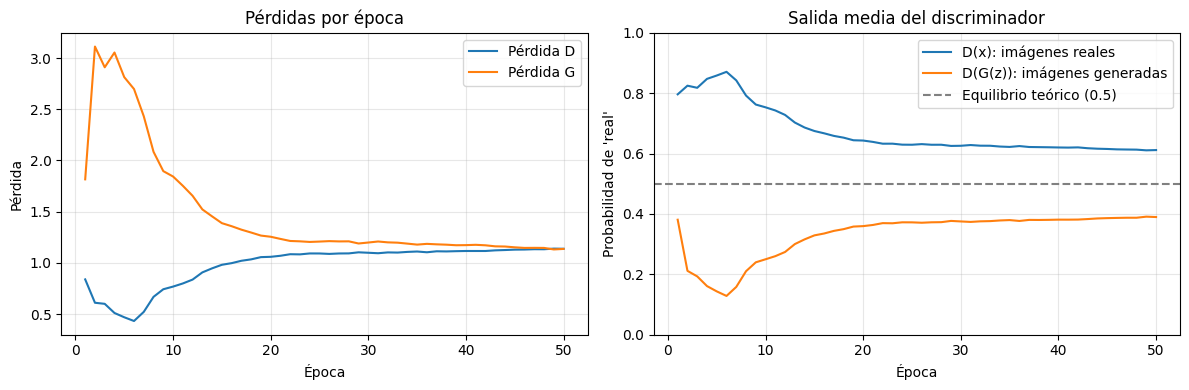

In [5]:
epocas = range(1, EPOCHS + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epocas, history["d_loss"], label="Pérdida D")
ax[0].plot(epocas, history["g_loss"], label="Pérdida G")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida"); ax[0].set_title("Pérdidas por época"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epocas, history["d_real"], label="D(x): imágenes reales")
ax[1].plot(epocas, history["d_fake"], label="D(G(z)): imágenes generadas")
ax[1].axhline(0.5, color="gray", linestyle="--", label="Equilibrio teórico (0.5)")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Probabilidad de 'real'"); ax[1].set_ylim(0, 1)
ax[1].set_title("Salida media del discriminador"); ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "curvas_entrenamiento.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Evolución de las muestras generadas
Se usa siempre el mismo ruido `z` fijo, de modo que las diferencias entre columnas se deben solo al aprendizaje de G.

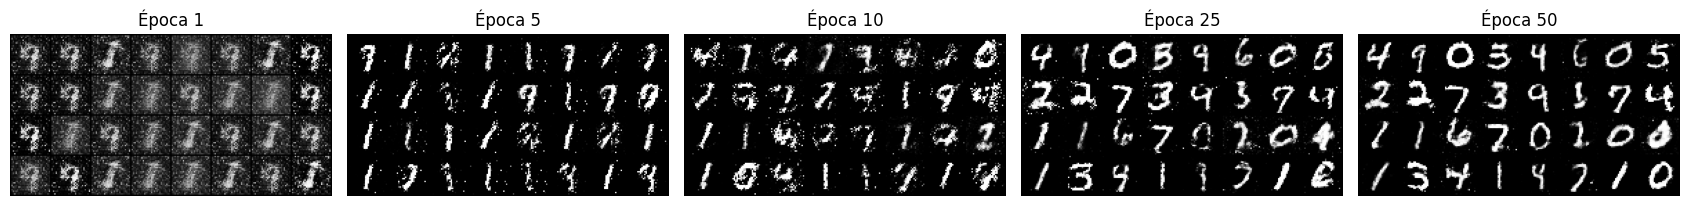

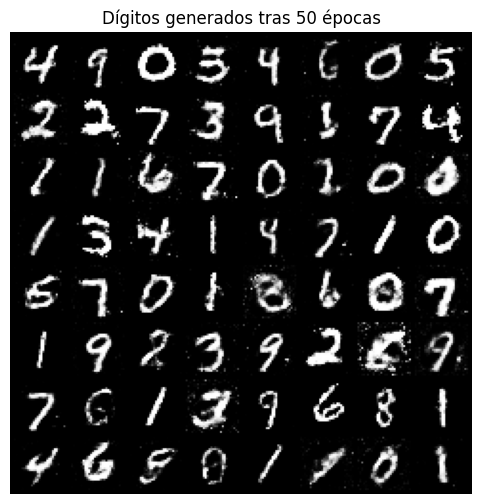

In [6]:
epocas_vistas = sorted(snapshots)
fig, axes = plt.subplots(1, len(epocas_vistas), figsize=(3.4 * len(epocas_vistas), 3.8))
if len(epocas_vistas) == 1:
    axes = [axes]
for ax, ep in zip(axes, epocas_vistas):
    grid = make_grid((snapshots[ep] + 1) / 2, nrow=8, padding=1)
    ax.imshow(grid[0], cmap="gray")
    ax.set_title(f"Época {ep}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "muestras_por_epoca.png"), dpi=150, bbox_inches="tight")
plt.show()

G.eval()
with torch.no_grad():
    finales = G(fixed_z)
mostrar_cuadricula(finales, f"Dígitos generados tras {EPOCHS} épocas", nombre="muestras_finales.png")

### 4.3 Evaluación con el discriminador
Se mide qué tan bien distingue D imágenes reales del conjunto de prueba (que no vio al entrenar) de 10 000 imágenes nuevas generadas por G. Una exactitud de D cercana al 50 % indicaría un generador muy convincente; cercana al 100 % indicaría que D todavía distingue fácilmente.

In [7]:
D.eval(); G.eval()
with torch.no_grad():
    probs_real = []
    for x, _ in test_loader:
        probs_real.append(torch.sigmoid(D(x.to(device))).squeeze(1).cpu())
    probs_real = torch.cat(probs_real)

    z_eval = torch.randn(10000, LATENT_DIM, device=device)
    fake_eval = G(z_eval)
    probs_fake = torch.sigmoid(D(fake_eval)).squeeze(1).cpu()

d_mean_real = probs_real.mean().item()
d_mean_fake = probs_fake.mean().item()
d_acc_real  = (probs_real > 0.5).float().mean().item()    # reales clasificadas como reales
d_acc_fake  = (probs_fake <= 0.5).float().mean().item()   # falsas clasificadas como falsas
d_acc_total = (d_acc_real + d_acc_fake) / 2

print(f"D(x) medio en test real      : {d_mean_real:.3f}")
print(f"D(G(z)) medio en falsas      : {d_mean_fake:.3f}")
print(f"Exactitud de D en reales     : {d_acc_real*100:.1f} %")
print(f"Exactitud de D en falsas     : {d_acc_fake*100:.1f} %")
print(f"Exactitud global de D (50/50): {d_acc_total*100:.1f} %")

D(x) medio en test real      : 0.553
D(G(z)) medio en falsas      : 0.331
Exactitud de D en reales     : 50.7 %
Exactitud de D en falsas     : 92.9 %
Exactitud global de D (50/50): 71.8 %


### 4.4 Verificación de diversidad (colapso de modos)
Un fallo típico de las GAN es el **colapso de modos**: G produce solo unos pocos tipos de imagen. Para detectarlo se entrena un clasificador sencillo de dígitos (CNN, 2 épocas, con las etiquetas de MNIST) y se mira qué dígitos reconoce en las 10 000 imágenes generadas. Si G es diverso, los 10 dígitos deberían aparecer con frecuencias parecidas (≈10 % cada uno, como en los datos reales).

> Es una **medida aproximada**, no una métrica estándar como FID. La confianza del clasificador es un indicador indirecto de qué tan "reconocibles" son los dígitos.

Exactitud del clasificador en MNIST test : 98.66 %
Confianza media en imágenes reales       : 0.983
Confianza media en imágenes generadas    : 0.920
% generadas con confianza < 0.9          : 23.0 %
Distribución de dígitos generados (%): [7.7, 19.3, 4.2, 9.0, 9.1, 6.8, 10.6, 13.3, 6.3, 13.8]


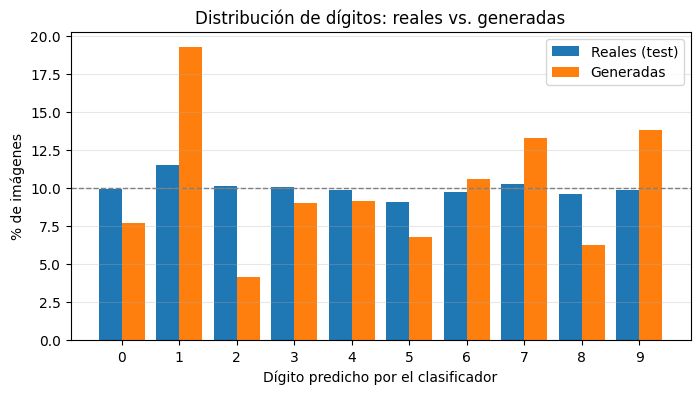

In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.head(self.features(x))

clf = SmallCNN().to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(2):
    clf.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(x), y)
        opt_c.zero_grad(); loss.backward(); opt_c.step()

clf.eval()
with torch.no_grad():
    preds_real, conf_real_list = [], []
    correct = 0
    for x, y in test_loader:
        p = F.softmax(clf(x.to(device)), dim=1).cpu()
        c, pr = p.max(1)
        correct += (pr == y).sum().item()
        preds_real.append(pr); conf_real_list.append(c)
    preds_real = torch.cat(preds_real); conf_real = torch.cat(conf_real_list)
    clf_acc = correct / len(test_ds)

    p_fake = F.softmax(clf(fake_eval), dim=1).cpu()
    conf_fake, preds_fake = p_fake.max(1)

share_real = torch.bincount(preds_real, minlength=10).float() / len(preds_real) * 100
share_fake = torch.bincount(preds_fake, minlength=10).float() / len(preds_fake) * 100

print(f"Exactitud del clasificador en MNIST test : {clf_acc*100:.2f} %")
print(f"Confianza media en imágenes reales       : {conf_real.mean().item():.3f}")
print(f"Confianza media en imágenes generadas    : {conf_fake.mean().item():.3f}")
print(f"% generadas con confianza < 0.9          : {(conf_fake < 0.9).float().mean().item()*100:.1f} %")
print("Distribución de dígitos generados (%):", [round(v, 1) for v in share_fake.tolist()])

idx = np.arange(10)
plt.figure(figsize=(8, 4))
plt.bar(idx - 0.2, share_real.numpy(), width=0.4, label="Reales (test)")
plt.bar(idx + 0.2, share_fake.numpy(), width=0.4, label="Generadas")
plt.axhline(10, color="gray", linestyle="--", linewidth=1)
plt.xticks(idx); plt.xlabel("Dígito predicho por el clasificador"); plt.ylabel("% de imágenes")
plt.title("Distribución de dígitos: reales vs. generadas"); plt.legend(); plt.grid(alpha=.3, axis="y")
plt.savefig(os.path.join(OUT_DIR, "distribucion_clases.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Interpolación en el espacio latente
Se toman dos vectores `z` y se generan imágenes para puntos intermedios de la recta que los une. Transiciones suaves indican que G aprendió una representación continua y no solo memorizó ejemplos.

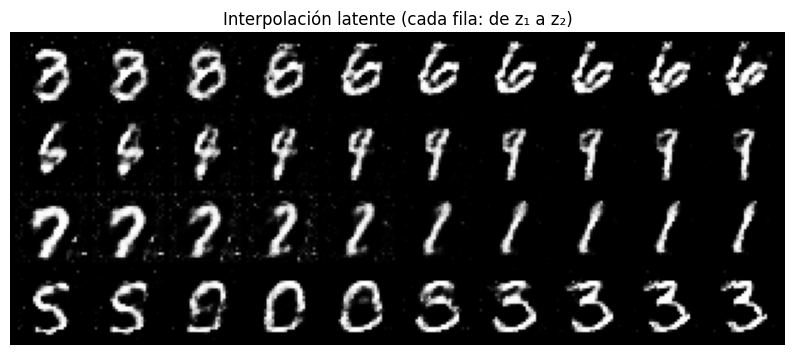

In [9]:
torch.manual_seed(SEED + 1)
filas = []
for _ in range(4):
    z1 = torch.randn(1, LATENT_DIM, device=device)
    z2 = torch.randn(1, LATENT_DIM, device=device)
    alphas = torch.linspace(0, 1, 10, device=device).view(-1, 1)
    z_interp = (1 - alphas) * z1 + alphas * z2
    with torch.no_grad():
        filas.append(G(z_interp).cpu())
interp = torch.cat(filas)
mostrar_cuadricula(interp, "Interpolación latente (cada fila: de z₁ a z₂)", nrow=10, nombre="interpolacion.png", size=10)

## 5. Guardar resultados
Esta celda guarda las métricas en `resultados.json`, empaqueta todo en `resultados_gan.zip` e intenta descargarlo. Al final imprime un **resumen con las cifras que se copian al informe**.

In [10]:
resumen = {
    "dispositivo": gpu_name,
    "semilla": SEED,
    "hiperparametros": {"epocas": EPOCHS, "batch": BATCH_SIZE, "lr": LR, "betas": list(BETAS), "latente": LATENT_DIM},
    "parametros": {"generador": n_params_G, "discriminador": n_params_D},
    "tiempo_entrenamiento_min": round(train_time / 60, 2),
    "ultima_epoca": {
        "d_loss": history["d_loss"][-1], "g_loss": history["g_loss"][-1],
        "d_real": history["d_real"][-1], "d_fake": history["d_fake"][-1],
    },
    "evaluacion_D": {"d_medio_real": d_mean_real, "d_medio_falsas": d_mean_fake,
                     "exactitud_reales": d_acc_real, "exactitud_falsas": d_acc_fake, "exactitud_global": d_acc_total},
    "clasificador": {"exactitud_test": clf_acc,
                     "confianza_reales": conf_real.mean().item(), "confianza_generadas": conf_fake.mean().item(),
                     "pct_generadas_conf_menor_0_9": (conf_fake < 0.9).float().mean().item() * 100,
                     "distribucion_generadas_pct": [round(v, 2) for v in share_fake.tolist()]},
    "historial": history,
}
with open(os.path.join(OUT_DIR, "resultados.json"), "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)

zip_name = "resultados_gan.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for fn in sorted(os.listdir(OUT_DIR)):
        zf.write(os.path.join(OUT_DIR, fn), arcname=fn)

try:
    from google.colab import files
    files.download(zip_name)
except Exception:
    print("(Fuera de Colab: el zip quedó en", os.path.abspath(zip_name), ")")

mx, mn = share_fake.max().item(), share_fake.min().item()
print("=" * 60)
print("RESUMEN PARA EL INFORME (Tabla de métricas finales)")
print("=" * 60)
print(f"Dispositivo de ejecución .................. {gpu_name}")
print(f"Tiempo de entrenamiento ................... {train_time/60:.1f} min")
print(f"Parámetros G / D .......................... {n_params_G:,} / {n_params_D:,}")
print(f"Pérdida D (época {EPOCHS}) .................... {history['d_loss'][-1]:.3f}")
print(f"Pérdida G (época {EPOCHS}) .................... {history['g_loss'][-1]:.3f}")
print(f"D(x) medio, entrenamiento (época {EPOCHS}) .... {history['d_real'][-1]:.3f}")
print(f"D(G(z)) medio, entrenamiento (época {EPOCHS}) . {history['d_fake'][-1]:.3f}")
print(f"Exactitud de D en reales (test) ........... {d_acc_real*100:.1f} %")
print(f"Exactitud de D en generadas ............... {d_acc_fake*100:.1f} %")
print(f"Exactitud del clasificador (MNIST test) ... {clf_acc*100:.2f} %")
print(f"Confianza clasificador, reales ............ {conf_real.mean().item():.3f}")
print(f"Confianza clasificador, generadas ......... {conf_fake.mean().item():.3f}")
print(f"% generadas con confianza < 0.9 ........... {(conf_fake < 0.9).float().mean().item()*100:.1f} %")
print(f"Dígito generado más frecuente / menos ..... {mx:.1f} % (dígito {int(share_fake.argmax())}) / {mn:.1f} % (dígito {int(share_fake.argmin())})")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

RESUMEN PARA EL INFORME (Tabla de métricas finales)
Dispositivo de ejecución .................. Tesla T4
Tiempo de entrenamiento ................... 13.2 min
Parámetros G / D .......................... 1,486,352 / 1,460,225
Pérdida D (época 50) .................... 1.138
Pérdida G (época 50) .................... 1.137
D(x) medio, entrenamiento (época 50) .... 0.612
D(G(z)) medio, entrenamiento (época 50) . 0.390
Exactitud de D en reales (test) ........... 50.7 %
Exactitud de D en generadas ............... 92.9 %
Exactitud del clasificador (MNIST test) ... 98.66 %
Confianza clasificador, reales ............ 0.983
Confianza clasificador, generadas ......... 0.920
% generadas con confianza < 0.9 ........... 23.0 %
Dígito generado más frecuente / menos ..... 19.3 % (dígito 1) / 4.2 % (dígito 2)


## 6. Preguntas guía para el análisis (para el informe)
1. ¿Cómo cambian las muestras entre la época 1 y la última? ¿En qué época empiezan a verse dígitos reconocibles?
2. ¿Se acercaron D(x) y D(G(z)) a 0.5, o uno de los dos dominó? ¿Qué significa eso en términos de equilibrio?
3. ¿La pérdida de G o de D bajó de forma constante? ¿Por qué no sirve como única medida de calidad?
4. ¿Aparecen los 10 dígitos con frecuencias parecidas? ¿Hay señales de colapso de modos?
5. ¿Las interpolaciones son suaves? ¿Qué dice eso sobre el espacio latente?
6. ¿Qué cambiarías (arquitectura convolucional, más épocas, otros hiperparámetros) para mejorar el resultado?